# Introducción

Los algoritmos de clasificación, son mecanismos de aprendizaje supervisados. Un algoritmo de aprendizaje supervisado quiere decir que debemos proporcionar al modelo un array con los datos resultantes de la matriz X proporcionada, de modo que el modelo pueda aprender a llegar a ese resultado con los datos proporcionados.


In [1]:
import pandas as pd

df = pd.read_excel("titanic3.xls")

df.head()
df = df.drop(columns=[
    "name",
    "ticket",
    "body",
    "boat",
    "home.dest",
    "cabin"
])

df = pd.get_dummies(df)

y = df.survived
X = df.drop(columns=["survived"])
X.head(3)

,pclass,age,sibsp,parch,fare,sex_female,sex_male,embarked_C,embarked_Q,embarked_S
0,1,29.0000,0,0,211.3375,True,False,False,False,True
1,1,0.9167,1,2,151.5500,False,True,False,False,True
2,1,2.0000,1,2,151.5500,True,False,False,False,True


In [2]:
from sklearn.model_selection import train_test_split
from sklearn.experimental import enable_iterative_imputer
from sklearn import impute
num_cols = [
    "pclass",
    "age",
    "sibsp",
    "parch",
    "fare",
    "sex_female"
]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

imputer = impute.IterativeImputer()
imputed = imputer.fit_transform(X_train[num_cols])
X_train[num_cols] = imputed
imputed = imputer.transform(X_test[num_cols])
X_test[num_cols] = imputed

In [3]:
from sklearn.preprocessing import StandardScaler

cols = [
    "age",
    "pclass",
    "sibsp",
    "fare"
]

sca = StandardScaler()
X_train[cols] = sca.fit_transform(X_train[cols])
X_test[cols] = sca.transform(X_test[cols])

# Regresión Logistica


A pesar de que tenga la palabra "regresión" en el nombre, es un algoritmo usado para tareas de clasificación

## Importación e instanciación

`Scikitlearn` provee la clase LogisticRegression en su paquete linear_model, usamos `random_state` para fijar una semilla aleatoria que permita facil reproducibilidad

In [4]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(random_state=42, verbose=1)

## Entrenamiento y puntuación

In [5]:
lr.fit(X_train, y_train)


,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"verbose verbose: int, default=0For the liblinear and lbfgs solvers set verbose to any positivenumber for verbosity.",1
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algori

In [6]:
lr.score(X_test, y_test)

0.8015267175572519

## Ejecutar predicciones

Antes de proceder a la ejecución de la predicciónm, demos una mirada a la matriz inicial, llamamos el atributo iloc en la fila 0 tanto para X como para y para saber que deberia predecir el modelo.

---

Recordando que hace el atributo illoc en pandas: Permite recuperar uno o varios registros del dataset indicados por un indice númerico, ademas de una o más columnas igualmente mediante su indice númerico.

Recuperar 

```python
# Usando la sintaxis de corchetes internos, se obtiene un dataframe nuevo

# Recuperar primera fila
X.iloc[[0]]

# Recuperar primera fila, primera columna
X.iloc[[0], [0]]

# Recuperar todas las filas, primera columna
X.iloc[:, [0]]

# Recuperar desde la primera fila, 3 filas (slicing) y primera columna
X.iloc[0:3, [0]]

# Rcuperar un slicing con las primeras 3 filas, y las columnas 0, 2 y 3
X.iloc[0:3, [0, 2, 3]]

# Recuperar un slice de las 3 primeras filas y las primera columna
X.iloc[0:3, :1]
```

In [7]:
X.head()

,pclass,age,sibsp,parch,fare,sex_female,sex_male,embarked_C,embarked_Q,embarked_S
0,1,29.0000,0,0,211.3375,True,False,False,False,True
1,1,0.9167,1,2,151.5500,False,True,False,False,True
2,1,2.0000,1,2,151.5500,True,False,False,False,True
3,1,30.0000,1,2,151.5500,False,True,False,False,True
4,1,25.0000,1,2,151.5500,True,False,False,False,True


In [8]:
X.iloc[0:3, :1]

,pclass
0,1
1,1
2,1


In [9]:
y.iloc[[0]]

0    1
Name: survived, dtype: int64

In [10]:
lr.predict(X.iloc[[0]])

array([1])

## Explorando el modelo resultante

Luego de ejecutar el entrenamiento, se puede explorar un poco el modelo resultante para conocer los resultados internos

In [11]:
# Muestra los coeficientes o "pesos" guardados para cada atributo del dataset
lr.coef_

array([[-0.73863871, -0.29429547, -0.27521844, -0.07498552,  0.09804532,
         1.16376157, -1.30922285,  0.34043658, -0.27458874, -0.23846575]])

In [12]:
# Muestra el valor intercepto b de la función lineal
lr.intercept_

array([-0.16951343])

In [13]:
# Muestra el número de iteraciones que requirió el entrenamiento para converger
lr.n_iter_

array([11], dtype=int32)

In [14]:
# NOTA: este atributo muestra únicamente las clases que busca predecir el modelo, no las columnas
lr.classes_

array([0, 1])

In [15]:
lr.predict_proba(X.iloc[[0]])

array([[5.01421849e-06, 9.99994986e-01]])

In [16]:
from yellowbrick.model_selection.importances import FeatureImportances

/home/gjae/miniconda3/envs/venv/lib/python3.15/site-packages/yellowbrick/model_selection/importances.py:194: YellowbrickWarning: detected multi-dimensional feature importances but stack=False, using mean to aggregate them.
  warnings.warn(


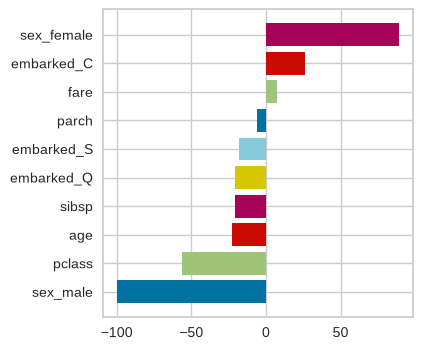

In [17]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(4,4))

fiv = FeatureImportances(lr, is_fitted=True)
fiv.fit(X, y)
fig.savefig("images/logreg_featureimportance.png", dpi=300)

/home/gjae/miniconda3/envs/venv/lib/python3.15/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(
/home/gjae/miniconda3/envs/venv/lib/python3.15/site-packages/yellowbrick/model_selection/importances.py:194: YellowbrickWarning: detected multi-dimensional feature importances but stack=False, using mean to aggregate them.
  warnings.warn(


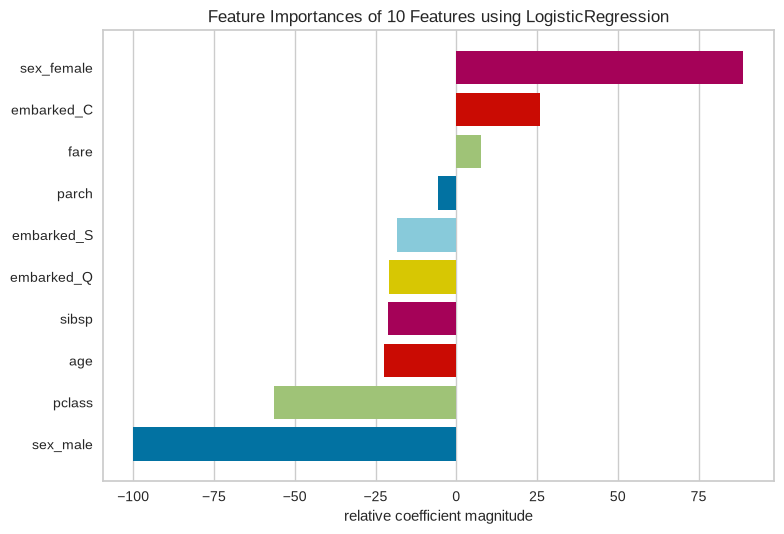

,estimator,"LogisticRegre...42, verbose=1)"
,ax,<Axes: title=...nt magnitude'>
,labels,None
,relative,True
,absolute,False
,xlabel,None
,stack,False
,colors,None
,colormap,None
,is_fitted,'auto'
,topn,None


In [18]:
from yellowbrick.model_selection import feature_importances

feature_importances(lr, X, y)

In [19]:
lr.feature_names_in_

array(['pclass', 'age', 'sibsp', 'parch', 'fare', 'sex_female',
       'sex_male', 'embarked_C', 'embarked_Q', 'embarked_S'], dtype=object)

In [20]:
lr.n_features_in_

10

# Naive Bayes

Es una familia compuesta principalmente por 3 modelos contenidos en scikitlearn
- GaussianNB: para distribuciones normales, valores continuos sobre una distribución normal
- MultinomialNB: para conteo de variables discretas
- BernouliNB: para variables continuas booleanas

* Funciona mejor si antes de entrenarlo, se eliminan las columnas colineares
* Puede exhibir alto sesgo y baja varianza

---

Esta familia de modelos tiende a asumir que todas las features en el dataset son independiente, gracias a eso, suelse ser comun para tareas de clasificación de texto tales como detección de spam. Además, funciona bien en entornos con pocas muestras

## Otras observaciones

Esta familia de modelo puede realizar actualizaciones en caliente usando ```partial_fit``` 

In [21]:
from sklearn.naive_bayes import GaussianNB

In [22]:
nb = GaussianNB()

In [23]:
nb.fit(X_train, y_train)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](2,)","[585.,331.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](2,)","[0.64,0.36]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[int64](2,)","[0,1]"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,1e-09
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](10,)","['pclass','age','sibsp',...,'embarked_C','embarked_Q','embarked_S']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,10
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](2, 10)","[[ 0.24,-0.01, 0.01,..., 0.15, 0.11, 0.75], [-0.42, 0.01,-0.02,..., 0.31, 0.08, 0.6 ]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](2, 10)","[[0.78,0.88,1.3 ,...,0.12,0.09,0.19], [1.11,1.21,0.47,...,0.21,0.08,0.24]]"


In [24]:
nb.predict(X.iloc[[0]])

array([1])

## Explorando el modelo resultante

In [25]:
nb.score(X_test, y_test)

0.7837150127226463

In [26]:
nb.predict_proba(X.iloc[[0]])

array([[0., 1.]])

In [27]:
nb.class_prior_

array([0.63864629, 0.36135371])

In [28]:
nb.class_count_

array([585., 331.])

In [29]:
nb.n_features_in_

10

In [30]:
nb.feature_names_in_

array(['pclass', 'age', 'sibsp', 'parch', 'fare', 'sex_female',
       'sex_male', 'embarked_C', 'embarked_Q', 'embarked_S'], dtype=object)

## Ejemplos de uso de las varianes NB

### Gaussian

Ideal para variables cuantitativas con decimales, como mediciones médicas o físicas.

In [31]:
import numpy as np
from sklearn.naive_bayes import GaussianNB

# Características: [Estatura en metros, Peso en kg]
# Muestra 1: Persona de 1.85m y 85kg
# Muestra 2: Persona de 1.60m y 55kg
X_gaussian = np.array([[1.85, 85.0], 
              [1.60, 55.0]])

# Clases (Target): 0 = Peso Normal, 1 = Sobrepeso
y_gaussian = np.array([1, 0])

clf = GaussianNB()
clf.fit(X_gaussian, y_gaussian)


,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](2,)","[1.,1.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](2,)","[0.5,0.5]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[int64](2,)","[0,1]"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,2.25e-07
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](2, 2)","[[ 1.6 ,55. ], [ 1.85,85. ]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](2, 2)","[[0.,0.], [0.,0.]]"


### Multinomial 

Ideal para contar cuántas veces ocurre un evento, como la frecuencia de palabras en un texto.

In [48]:
import numpy as np
from sklearn.naive_bayes import MultinomialNB

# Características: Frecuencia de las palabras ['descuento', 'reunión', 'dinero']
# Muestra 1: El correo tiene 3 veces 'descuento', 0 veces 'reunión', 2 veces 'dinero'
# Muestra 2: El correo tiene 0 veces 'descuento', 4 veces 'reunión', 1 vez 'dinero'
X_multinomial = np.array([[3, 0, 2], 
              [0, 4, 1]])

# Clases (Target): 0 = Correo Normal, 1 = Spam
y_multinomial = np.array([1, 0])

clf = MultinomialNB()
clf.fit(X_multinomial, y_multinomial)

,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)Number of samples encountered for each class during fitting. Thisvalue is weighted by the sample weight when provided.","ndarray[float64](2,)","[1.,1.]"
"class_log_prior_ class_log_prior_: ndarray of shape (n_classes,)Smoothed empirical log probability for each class.","ndarray[float64](2,)","[-0.69,-0.69]"
"classes_ classes_: ndarray of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"feature_count_ feature_count_: ndarray of shape (n_classes, n_features)Number of samples encountered for each (class, feature)during fitting. This value is weighted by the sample weight whenprovided.","ndarray[float64](2, 3)","[[0.,4.,1.], [3.,0.,2.]]"
"feature_log_prob_ feature_log_prob_: ndarray of shape (n_classes, n_features)Empirical log probability of featuresgiven a class, ``P(x_i|y)``.","ndarray[float64](2, 3)","[[-2.08,-0.47,-1.39], [-0.69,-2.08,-0.98]]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3


### Bernoulli

Ideal cuando solo importa saber si una característica existe (1) o no existe (0), sin importar su cantidad.

cada feature indica presencia o ausencia (true/false, 0/1)

In [49]:
import numpy as np
from sklearn.naive_bayes import BernoulliNB

# Características: Presencia (1) o Ausencia (0) de ['fiebre', 'tos', 'fractura']
# Muestra 1: El paciente tiene fiebre (1), tiene tos (1), NO tiene fractura (0)
# Muestra 2: El paciente NO tiene fiebre (0), NO tiene tos (0), tiene fractura (1)
X_bernoulli = np.array([[1, 1, 0], 
              [0, 0, 1]])

# Clases (Target): 0 = Traumatología, 1 = Medicina General
y_bernoulli = np.array([1, 0])

clf = BernoulliNB()
clf.fit(X_bernoulli, y_bernoulli)


,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"binarize binarize: float or None, default=0.0Threshold for binarizing (mapping to booleans) of sample features.If None, input is presumed to already consist of binary vectors.",0.0
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)Number of samples encountered for each class during fitting. Thisvalue is weighted by the sample weight when provided.","ndarray[float64](2,)","[1.,1.]"
"class_log_prior_ class_log_prior_: ndarray of shape (n_classes,)Log probability of each class (smoothed).","ndarray[float64](2,)","[-0.69,-0.69]"
"classes_ classes_: ndarray of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"feature_count_ feature_count_: ndarray of shape (n_classes, n_features)Number of samples encountered for each (class, feature)during fitting. This value is weighted by the sample weight whenprovided.","ndarray[float64](2, 3)","[[0.,0.,1.], [1.,1.,0.]]"
"feature_log_prob_ feature_log_prob_: ndarray of shape (n_classes, n_features)Empirical log probability of features given a class, P(x_i|y).","ndarray[float64](2, 3)","[[-1.1 ,-1.1 ,-0.41], [-0.41,-0.41,-1.1 ]]"


# Maquinas de soporte vectorial


En este algoritmo , el modelo busca ajustar lineas conocidas como hiperplano de modo que intenta maximizar el espacio entre los puntos y la frontera de decisión. Entre más alejado esta el punto de la muestra del hiperplano, más certeza tiene el modelo de que esa instancia pertenece a esa clase.

- Los puntos que estan junto a los hiperplanos se conocen como vectores de soporte
- Si los datos no son separables linealmente de forma perfecta. Se puede ajustar el modelo usando el conocido "truco del kernel"

In [50]:
from sklearn.svm import SVC

In [51]:
svc = SVC(random_state=42)

In [52]:
svc.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo random number generation for shuffling the data forprobability estimates. Ignored when `probability` is False.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None


In [53]:
svc.predict(X.iloc[[0]])

array([0])

In [54]:
svc.score(X_test, y_test)

0.8015267175572519

# KNN

K-nereast neighbor, es un algoritmo que se considera no parametrico, pertence a una familia de algoritmos llamados "aprendizaje basado en distancia" ya que usa predicciones basadas en el cálculo de la distancia de una muestra con respecto a un número (k) de muestras de entrenamiento.
En terminos de complejidad, para el entrenamiento se considera `O(1)` pero requiere almacenar los datos, mientras que para pruebas requiere una complejidad `O(Nd)` donde **N** es en número de muestras guardadas durante el entrenamiento y **d** dimensiones, por lo que es suseptible a altas dimensionalidades.

Además, trabaja mejor si los datos se encuentran normalizados.

In [92]:
from sklearn.neighbors import KNeighborsClassifier as KNN

In [93]:
knn = KNN()
knn.fit(X_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [94]:
knn.predict(X.iloc[[0]])

array([1])

In [95]:
knn.score(X_test, y_test)

0.7837150127226463

## Fine-tuning hiperparametros

Para optimizar el funcionamiento del modelo KNN, podemos intentar buscar el mejor set de parametros posibles

In [96]:
KNN(n_neighbors=20).fit(X_train, y_train).score(X_test, y_test)

0.7786259541984732

In [123]:
from sklearn.model_selection import GridSearchCV

knn_params = {
    "n_neighbors": [5, 10, 15, 20],
    "weights": ["uniform", "distance", None],
    "algorithm": ["auto", "ball_tree", "kd_tree", "brute"],
    "leaf_size": list(range(1, 60))
}

gscv = GridSearchCV(KNN(), knn_params)

In [124]:
gscv.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",KNeighborsClassifier()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'algorithm': ['auto', 'ball_tree', ...], 'leaf_size': [1, 2, ...], 'n_neighbors': [5, 10, ...], 'weights': ['uniform', 'distance', ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",No

In [125]:
gscv.best_score_

np.float64(0.7980517937752436)

In [126]:
gscv.best_params_

{'algorithm': 'ball_tree',
 'leaf_size': 3,
 'n_neighbors': 10,
 'weights': 'uniform'}

In [127]:
estimator = gscv.best_estimator_

In [128]:
estimator.score(X_test, y_test)

0.7888040712468194

In [129]:
KNN(**gscv.best_params_).fit(X_train, y_train).score(X_test, y_test)

0.7888040712468194

In [130]:
estimator

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",10
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'ball_tree'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",3
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


# Árboles de decisión

- Esta familia de algoritmos usa estructuras de árboles donde cada rama es un camino a una decisión y cada nodo hoja es una decisión concreta
- Tiende a ser menos susceptible a outliers, pero tiende a ser más propenso a sufrir de overfitting si no se regulariza adecuadamente
- Cuenta con la ventaja de que sus decisiones suelen ser más faciles de auditar y entender en comparación a otros algoritmos
- Utiliza un algoritmo llamado "Classifier And Regression Tree" (CART) el cual usa un mecanismo de medida llamado "Gini" para medir las respuesta e intentar disminuir la probabilidad de error en la clasificación

In [32]:
from sklearn.tree import DecisionTreeClassifier

In [33]:
tree = DecisionTreeClassifier(random_state=4)

tree.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",4
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples 

In [34]:
tree.score(X_test, y_test)

0.7659033078880407

In [36]:
tree.predict(X.iloc[[0]])

array([0])

## Regularización

Se puede especificar algunos hiperparametros para regularizar el árbol a fin de que tenga menor probabilidad de overfitting

- max_depth int, default=None: La profundidad máxima del árbol, si es None, los nodos se expandiran hasta que todas las hojas tengan una impureza menor que min_samples_split
- criterion {“gini”, “entropy”, “log_loss”}, default=”gini”: Indica la función de calidad de la división
- min_samples_split int or float, default=2: INdica el número minimo de muestras requeridas para generar una división nueva
- min_samples_leaf int or float, default=1: Número minimo de muestras requeridas para generar un nodo hoja

Algunas otras configuraciones están disponibles en la documentación de scikitlearn


In [40]:
tree2 = DecisionTreeClassifier(max_depth=3, criterion="gini")

tree2.fit(X_train, y_train)
tree2.score(X_test, y_test)

0.8142493638676844

In [41]:
tree2.predict(X.iloc[[0]])

array([0])

In [42]:
X.iloc[[0]]

,pclass,age,sibsp,parch,fare,sex_female,sex_male,embarked_C,embarked_Q,embarked_S
0,1,29.0,0,0,211.3375,True,False,False,False,True


In [44]:
y[0]

np.int64(1)

## Inspeccionando

In [45]:
tree2.classes_

array([0, 1])

In [46]:
tree2.feature_names_in_

array(['pclass', 'age', 'sibsp', 'parch', 'fare', 'sex_female',
       'sex_male', 'embarked_C', 'embarked_Q', 'embarked_S'], dtype=object)

In [47]:
tree2.feature_importances_

array([0.24750773, 0.0432777 , 0.05214257, 0.        , 0.05018218,
       0.        , 0.60688982, 0.        , 0.        , 0.        ])

In [49]:
for feature, imp in zip(X.columns, tree2.feature_importances_):
    print("%s : %.2f" % (feature, imp))

pclass : 0.25
age : 0.04
sibsp : 0.05
parch : 0.00
fare : 0.05
sex_female : 0.00
sex_male : 0.61
embarked_C : 0.00
embarked_Q : 0.00
embarked_S : 0.00


# RandomForest

Este es un ensamblaje, lo que quiere decir que usa varios modelos entrenados en puntos o columnas especifica para buscar tener un mejor desempeño en la predicción. Especificamente utiliza árboles de fondo, lo que quiere decir que genera un "bosque", lo que quiere decir que además de agregar hiperparametros especificos, también hereda los hiperparametros de los árboles individuales.

In [58]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=2, random_state=42)

In [59]:
rf.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",2
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap

In [60]:
rf.score(X_test, y_test)

0.7073791348600509

In [61]:
rf.predict(X.iloc[[0]])

array([0])

# XGBoost

Extreme-Gradiant Boosting, es un modelo externo a scikitlearn que utiliza también modelos de árboles por debajo, aunque scikitlearn provee un algoritmo GradiantBoosting, se suele usar una librería externa que provee mejores resultados

In [65]:
import xgboost as xgb

boost = xgb.XGBClassifier(random_state=42)

In [66]:
boost.fit(X_train, y_train)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [67]:
boost.score(X_test, y_test)

0.7989821882951654

In [68]:
boost.predict(X.iloc[[0]])

array([0])

# Menciones honorificas

Además de XGBoost, existen otras implementaciones que valen la pena tener en cuenta

- LightGBM: Implementación de microsoft
- TPOT: se basa en algoritmos geneticos
- AdaBoost: ofrecido en el paquete de ensemble de Scikitlearn, es un meta estimador que puede implementar regresión y clasificación
- HistGradiantBoosting: también incluido en scikitlearn, es mucho más eficientes para datasets  que superen las 10_000 muestras, cuenta con un estimador que tiene soporte para valores faltantes